# LankaEcon – Phase 4: Price Forecasting

**Goal:** forecast key Sri Lankan prices 1–6 months ahead, and measure honestly how good those forecasts are.

**Models** (`src/forecasting.py`)
| Model | Description |
|---|---|
| `naive` | last observed value |
| `seasonal_naive` | value 12 months before the target month |
| `sarima` | SARIMA on log price; order chosen by AIC on the **initial window only** |
| `sarimax` | SARIMA + lagged drivers validated in Phase 3 (LKR/USD, world food, world wheat, world sugar) |
| `lightgbm` | direct multi-horizon gradient boosting on lagged growth, calendar, lagged driver and regime features; **pooled** across the short CBSL-era items |

**Leakage guardrails**
- A forecast made at origin *t* uses only data dated ≤ *t*.
- Drivers enter with a ≥ 1-month lag. Future driver values not yet known at the information date are held at their last observed value.
- Fuel months flagged `possible_missing_revision` are never used, and fuel is not an input.
- Target gaps stay missing (no imputation), and no forecast is scored against a missing actual.

**Evaluation:** rolling-origin backtests (refit at every monthly origin), horizons 1–6, MAE / RMSE / MAPE. Forecasts whose **target month falls in the 2022 crisis window (2022-01 → 2023-06)** form a separate **stress test** and are excluded from routine scores.

The backtest itself is run by `scripts/09_forecast_backtest.py` (~4 min) and the optional LSTM check by `scripts/10_lstm_experiment.py`. This notebook reads their tables from `reports/tables/`. Set `RERUN = True` to run the backtest here instead.

In [1]:
import sys, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "forecasting.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import forecasting as F
import relationships as R

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "axes.titleweight": "bold"})
save = lambda fig, name: fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

RERUN = False
if RERUN or not (TAB / "phase4_backtest_forecasts.csv").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "09_forecast_backtest.py")], check=True)

bt = pd.read_csv(TAB / "phase4_backtest_forecasts.csv", parse_dates=["origin", "target_date"])
scores = pd.read_csv(TAB / "phase4_backtest_scores.csv")
specs_tab = pd.read_csv(TAB / "phase4_model_specs.csv")
fc = pd.read_csv(TAB / "phase4_forecasts.csv", parse_dates=["origin", "target_date"])
df = R.load_monthly()
cont = pd.read_csv(ROOT / "data" / "processed" / "commodity_prices_continuous_monthly.csv", parse_dates=["date"])
specs = {s.name: s for s in F.build_specs(df, cont)}
print(f"{len(bt):,} scored backtest forecasts across {bt['series'].nunique()} series")

24,777 scored backtest forecasts across 13 series


## 1. Series selection

In [2]:
sel = specs_tab[["series", "group", "n_origins", "first_origin", "last_origin", "note"]].copy()
sel["history"] = [f"{specs[s].y.first_valid_index():%Y-%m} → {specs[s].y.last_valid_index():%Y-%m}" for s in sel["series"]]
sel["months_observed"] = [int(specs[s].y.notna().sum()) for s in sel["series"]]
sel["forecastable"] = [specs[s].forecastable for s in sel["series"]]
sel["sarimax_drivers"] = [", ".join(specs[s].drivers) or "–" for s in sel["series"]]
display(sel[["series", "group", "history", "months_observed", "n_origins", "first_origin", "forecastable", "sarimax_drivers", "note"]])

,series,group,history,months_observed,n_origins,first_origin,forecastable,sarimax_drivers,note
0,CPI (cleaned),long,2000-01 → 2026-08,320,199,2010-01,True,"lkr_per_usd, world_food_index","drivers: FX (0.27→0.58 pass-through), world fo..."
1,LKR/USD,long,2000-01 → 2026-10,322,201,2010-01,True,–,macro driver; no external drivers
2,Rice (white),long,2006-07 → 2026-11,234,174,2011-06,True,–,gap 2022-07..2023-05 kept missing; Phase 3: no...
3,Wheat flour,long,2006-01 → 2022-06,198,138,2010-12,False,"lkr_per_usd, world_wheat_usd",ends 2022-06: backtest/stress test only
4,Coconut,recent,2022-07 → 2026-11,53,29,2024-06,True,–,domestic crop; no validated driver
5,Beans,recent,2022-07 → 2026-11,53,29,2024-06,True,–,seasonal vegetable
6,Carrots,recent,2022-07 → 2026-11,53,29,2024-06,True,–,seasonal vegetable
7,Tomatoes,recent,2022-07 → 2026-11,53,29,2024-06,True,–,seasonal vegetable
8,Cabbage,recent,2022-07 → 2026-11,53,29,2024-06,True,–,seasonal vegetable
9,Onions (imported),recent,2022-07 → 2026-11,53,29,2024-06,True,lkr_per_usd,"driver: FX (≈3.0, p=0.08)"


- **Long series** (CPI, LKR/USD, white rice, wheat flour) have 192–322 months of history and are backtested from 2010. Their backtests include the 2022 crisis stress test.
- **Wheat flour** ends in 2022-06, so it is used for backtesting and the stress test only, with no forward forecast.
- **White rice** has a gap from 2022-07 to 2023-05. It is left missing, not imputed.
- **Recent items** (eight vegetables/staples from the continuous series, from 2022-07; CBSL sugar from 2023-01) have about 47–53 months. They get a 24-month initial window and about 23–29 forecast origins, all after the crisis, so **no crisis stress test is possible for them**. LightGBM is **pooled** across these nine items to compensate for the short history.
- **Last month is partial:** the latest month for the recent items is 2026-11, which covers only CBSL reports to 2026-11-25.
- **SARIMAX** is used only where Phase 3 found a significant driver. Rice, coconut and the vegetables have none.

## 2. Routine accuracy (crisis targets excluded)

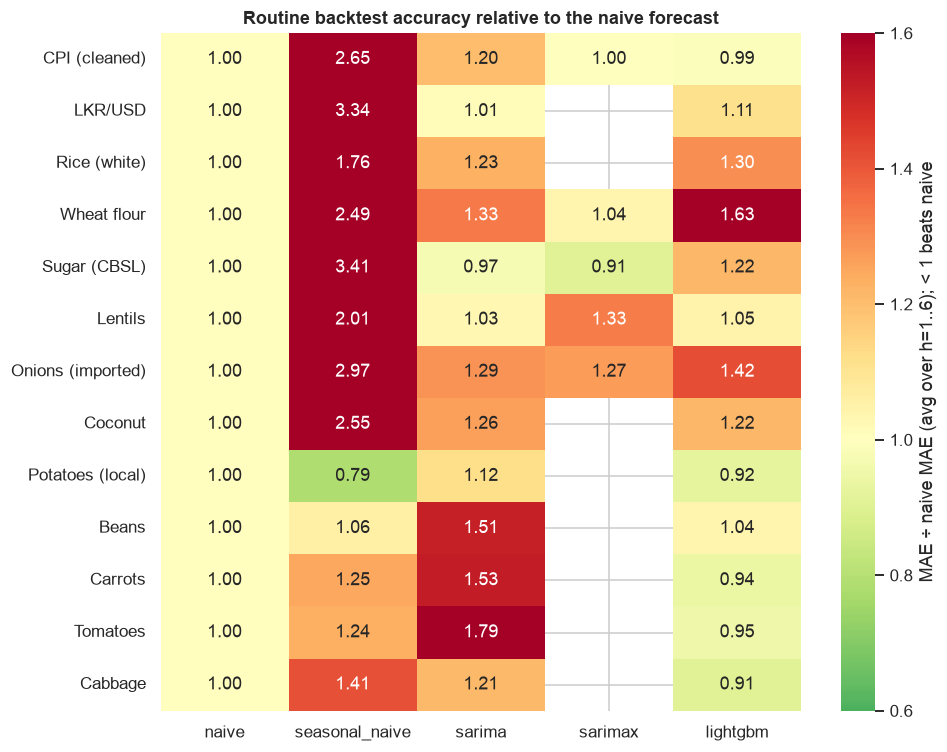

In [3]:
routine = scores[scores["regime"] == "routine"]
rel = routine.groupby(["series", "model"])["MAE_vs_naive"].mean().unstack()
rel = rel[["naive", "seasonal_naive", "sarima", "sarimax", "lightgbm"]]
order = ["CPI (cleaned)", "LKR/USD", "Rice (white)", "Wheat flour", "Sugar (CBSL)", "Lentils", "Onions (imported)",
         "Coconut", "Potatoes (local)", "Beans", "Carrots", "Tomatoes", "Cabbage"]
rel = rel.reindex(order)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1, vmin=0.6, vmax=1.6, ax=ax,
            cbar_kws={"label": "MAE ÷ naive MAE (avg over h=1..6); < 1 beats naive"})
ax.set_title("Routine backtest accuracy relative to the naive forecast"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); save(fig, "19_backtest_relative_mae")

In [4]:
best_h = F.best_by_horizon(scores)
piv = best_h.pivot(index="series", columns="horizon", values="best_model").reindex(order)
gain = best_h.pivot(index="series", columns="horizon", values="MAE_vs_naive").reindex(order)
display(piv.add_prefix("h"))
display(gain.add_prefix("h").round(2).rename_axis("best model MAE ÷ naive MAE"))
mape = pd.read_csv(TAB / "phase4_backtest_scores_all_horizons.csv")
display(mape[mape["regime"] == "routine"].pivot(index="series", columns="model", values="MAPE_%").reindex(order).round(1)
        .rename_axis("routine MAPE % (h=1..6)"))

horizon,h1,h2,h3,h4,h5,h6
series,,,,,,
CPI (cleaned),lightgbm,lightgbm,lightgbm,naive,naive,sarimax
LKR/USD,sarima,sarima,naive,naive,naive,naive
Rice (white),naive,naive,naive,naive,naive,naive
Wheat flour,naive,naive,naive,naive,naive,naive
Sugar (CBSL),sarimax,sarimax,sarimax,sarimax,sarimax,sarimax
Lentils,naive,naive,naive,lightgbm,lightgbm,lightgbm
Onions (imported),naive,naive,naive,naive,naive,naive
Coconut,naive,naive,naive,naive,naive,naive
Potatoes (local),sarima,seasonal_naive,seasonal_naive,seasonal_naive,seasonal_naive,seasonal_naive


horizon,h1,h2,h3,h4,h5,h6
best model MAE ÷ naive MAE,,,,,,
CPI (cleaned),0.880,0.910,0.970,1.000,1.000,0.990
LKR/USD,0.940,0.980,1.000,1.000,1.000,1.000
Rice (white),1.000,1.000,1.000,1.000,1.000,1.000
Wheat flour,1.000,1.000,1.000,1.000,1.000,1.000
Sugar (CBSL),0.800,0.880,0.900,0.930,0.960,0.960
Lentils,1.000,1.000,1.000,0.910,0.860,0.890
Onions (imported),1.000,1.000,1.000,1.000,1.000,1.000
Coconut,1.000,1.000,1.000,1.000,1.000,1.000
Potatoes (local),0.870,0.650,0.650,0.660,0.760,0.940


model,lightgbm,naive,sarima,sarimax,seasonal_naive
routine MAPE % (h=1..6),,,,,
CPI (cleaned),1.700,1.800,2.200,1.800,4.600
LKR/USD,2.400,2.100,2.100,NaN,5.600
Rice (white),6.100,4.900,5.700,NaN,7.900
Wheat flour,4.700,2.700,3.800,2.800,6.300
Sugar (CBSL),4.400,3.700,3.600,3.400,11.100
Lentils,4.500,4.500,4.500,6.000,8.300
Onions (imported),34.000,23.300,31.200,29.300,62.400
Coconut,15.900,13.400,18.000,NaN,29.000
Potatoes (local),9.900,11.100,12.000,NaN,8.300


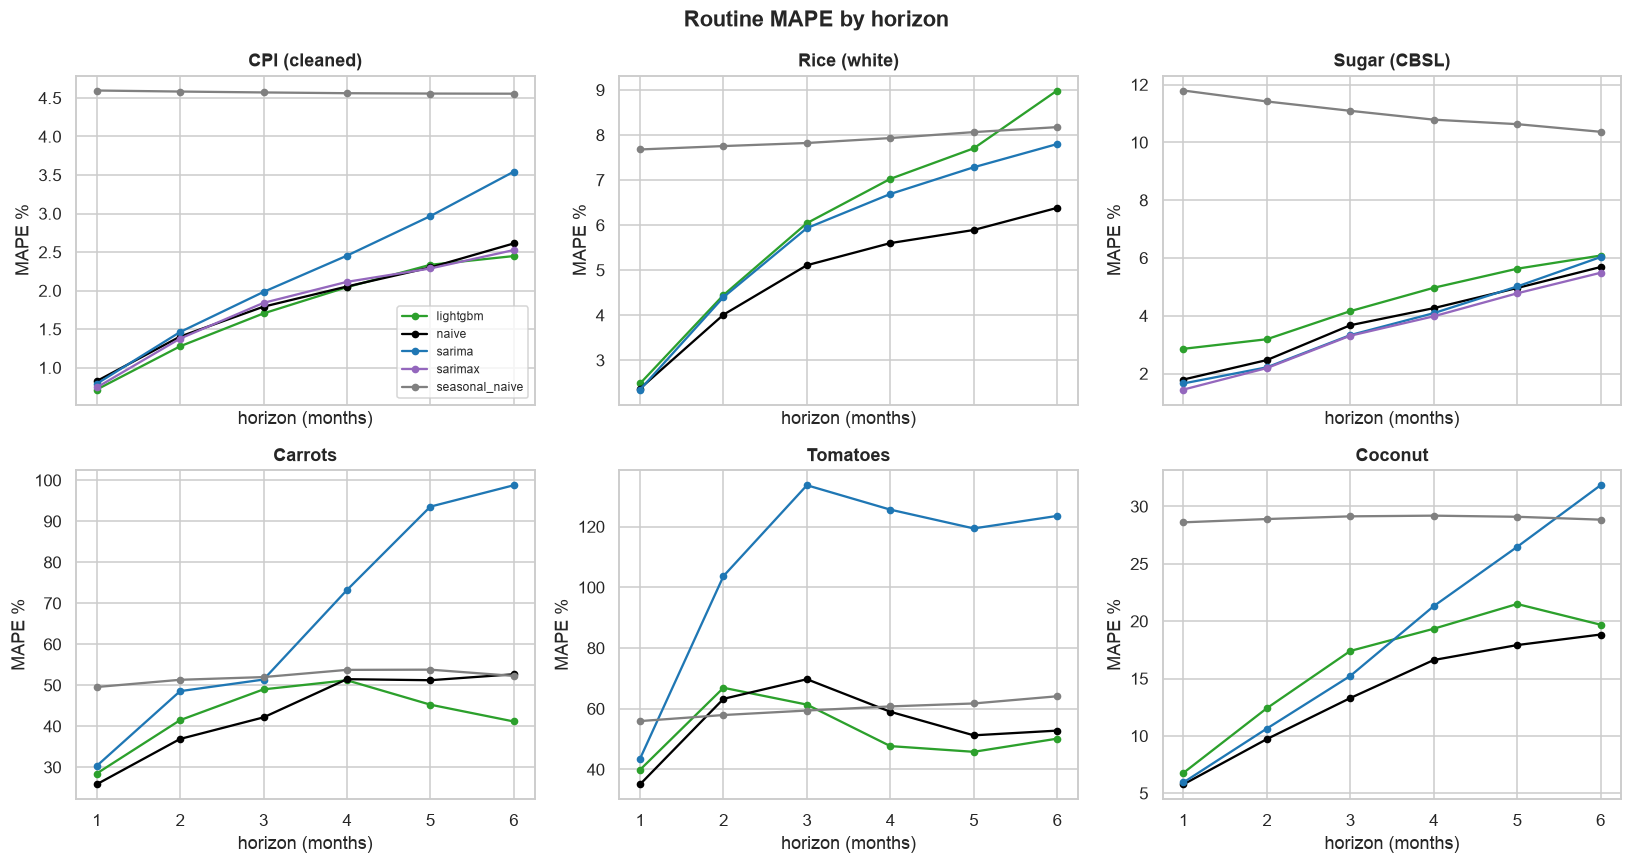

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
colors = {"naive": "black", "seasonal_naive": "grey", "sarima": "tab:blue", "sarimax": "tab:purple", "lightgbm": "tab:green"}
for ax, s in zip(axes.flat, ["CPI (cleaned)", "Rice (white)", "Sugar (CBSL)", "Carrots", "Tomatoes", "Coconut"]):
    d = routine[routine["series"] == s]
    for m, g in d.groupby("model"):
        ax.plot(g["horizon"], g["MAPE_%"], "o-", color=colors[m], label=m, ms=4)
    ax.set_title(s); ax.set_xlabel("horizon (months)"); ax.set_ylabel("MAPE %")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Routine MAPE by horizon", fontweight="bold"); fig.tight_layout(); save(fig, "20_mape_by_horizon")

## 3. Crisis stress test (targets in 2022-01 → 2023-06)

Only the long series cover the crisis. The table compares MAPE on crisis targets with MAPE on routine targets, for the same models and horizons.

regime                crisis_2022                                       routine                                    
model                    lightgbm  naive sarima sarimax seasonal_naive lightgbm naive sarima sarimax seasonal_naive
series        horizon                                                                                              
CPI (cleaned) 1             2.500  2.700  1.700   1.700         29.700    0.700 0.800  0.800   0.700          4.600
              3             9.700  7.800  6.200   6.300         29.700    1.700 1.800  2.000   1.800          4.600
              6            15.000 15.300 13.200  13.700         29.700    2.400 2.600  3.500   2.500          4.600
LKR/USD       1             5.900  4.100  4.000     NaN         31.700    0.800 0.800  0.700     NaN          5.600
              3            14.800 11.000 13.000     NaN         31.700    2.100 1.900  1.900     NaN          5.600
              6            19.400 19.100 24.100     NaN         31.700    3.900 3.500  3.600     NaN          5.700
Rice (white)  1             7.500  8.500  7.800     NaN         43.100    2.500 2.400  2.300     NaN          7.700
              3            23.900 23.800 17.600     NaN         43.100    6.000 5.100  5.900     NaN          7.800
              6            35.400 38.000 33.800     NaN         43.100    9.000 6.400  7.800     NaN          8.200
Wheat flour   1             7.300 11.300  7.100   9.100         53.200    2.100 1.400  1.700   1.600          6.600
              3            23.300 30.900 27.400  30.200         53.200    4.300 2.600  3.500   2.700          6.400
              6            42.700 46.400 44.200  46.100         53.200    7.100 3.800  5.700   3.800          5.900

Crisis-target forecasts per series and horizon: {'CPI (cleaned)': 18.0, 'LKR/USD': 18.0, 'Rice (white)': 6.0, 'Wheat flour': 6.0}


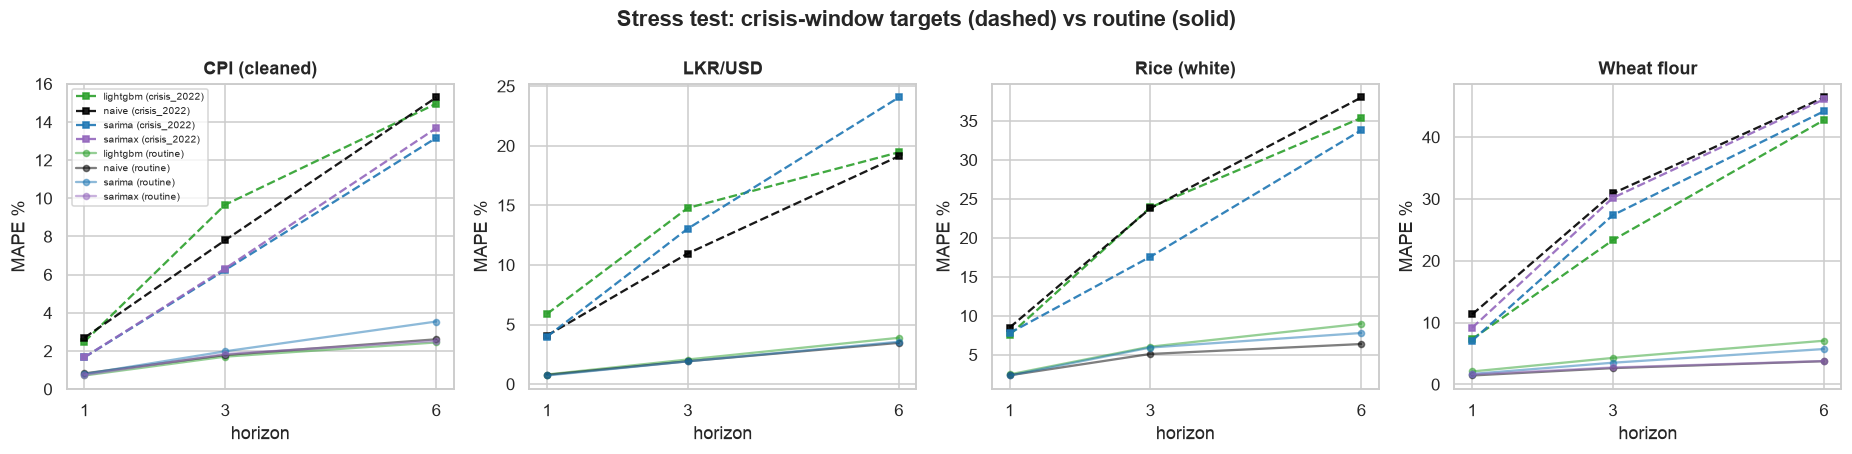

In [6]:
crisis = scores[scores["regime"] == "crisis_2022"]
long_series = ["CPI (cleaned)", "LKR/USD", "Rice (white)", "Wheat flour"]
st = scores[scores["series"].isin(long_series) & scores["horizon"].isin([1, 3, 6])]
tab = st.pivot_table(index=["series", "horizon"], columns=["regime", "model"], values="MAPE_%").round(1)
display(tab)
print("Crisis-target forecasts per series and horizon:", crisis.groupby("series")["n"].max().to_dict())

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=False)
for ax, s in zip(axes, long_series):
    d = st[(st["series"] == s) & (st["model"] != "seasonal_naive")]
    p = d.pivot_table(index=["horizon"], columns=["regime", "model"], values="MAPE_%")
    for (reg, m) in p.columns:
        ax.plot(p.index, p[(reg, m)], "o-" if reg == "routine" else "s--", color=colors[m], ms=4,
                alpha=0.9 if reg == "crisis_2022" else 0.5, label=f"{m} ({reg})")
    ax.set_title(s); ax.set_xlabel("horizon"); ax.set_ylabel("MAPE %"); ax.set_xticks([1, 3, 6])
axes[0].legend(fontsize=6.5, ncol=1)
fig.suptitle("Stress test: crisis-window targets (dashed) vs routine (solid)", fontweight="bold")
fig.tight_layout(); save(fig, "21_crisis_stress_test")

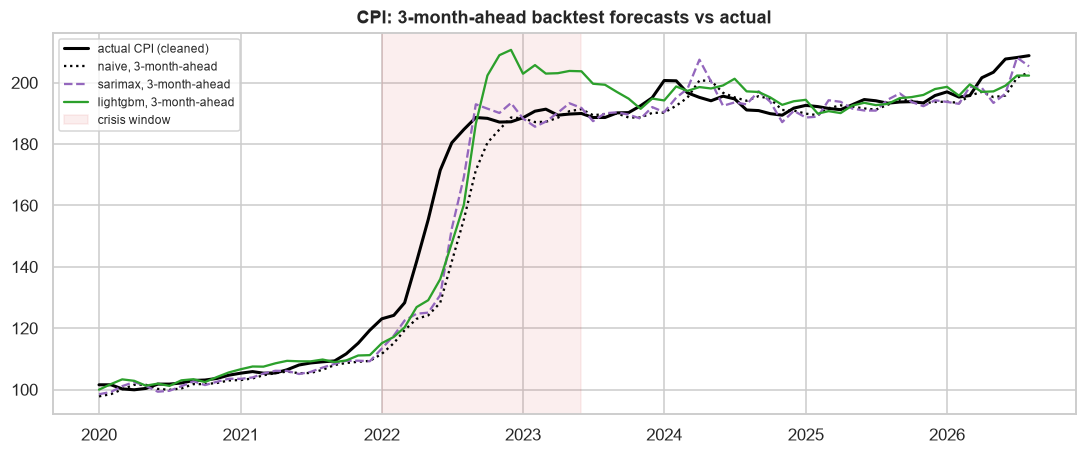

In [7]:
# What the 1- and 3-month CPI forecasts looked like through the crisis
fig, ax = plt.subplots(figsize=(12, 4.5))
y = specs["CPI (cleaned)"].y.loc["2020":]
ax.plot(y.index, y, color="black", lw=2, label="actual CPI (cleaned)")
for m, h, st_ in [("naive", 3, ":"), ("sarimax", 3, "--"), ("lightgbm", 3, "-")]:
    d = bt[(bt["series"] == "CPI (cleaned)") & (bt["model"] == m) & (bt["horizon"] == h)].set_index("target_date")["forecast"].loc["2020":]
    ax.plot(d.index, d, st_, color=colors[m], label=f"{m}, 3-month-ahead")
ax.axvspan(F.CRISIS[0], F.CRISIS[1], color="tab:red", alpha=0.08, label="crisis window")
ax.set_title("CPI: 3-month-ahead backtest forecasts vs actual"); ax.legend(fontsize=8)
save(fig, "22_cpi_backtest_path")

## 4. Optional LSTM check

A compact LSTM (24-month input window, direct 6-month output, 3-seed ensemble, refit every 12 months) was trained on the two longest series. It was scored on exactly the same routine forecasts as the other models (`scripts/10_lstm_experiment.py`).

In [8]:
lstm = pd.read_csv(TAB / "phase4_lstm_check.csv", index_col=0)
display(lstm.rename_axis("routine MAE (same forecasts)"))

,CPI (cleaned),Rice (white)
routine MAE (same forecasts),,
lightgbm,1.982,5.595
lstm,2.030,8.141
naive,1.966,4.545
sarima,2.464,5.698
sarimax,1.973,NaN
seasonal_naive,4.527,7.388
n_forecasts,"1,071.000",828.000


The LSTM **does not beat the naive model on CPI (2.03 vs 1.97) and is far worse on rice (8.14 vs 4.55)**. With one to two hundred monthly observations there isn't enough data to train a recurrent network reliably. **The LSTM is therefore not included in the model set.**

## 5. Forecasts for the next 6 months

The **selected forecast** uses, at each horizon, the model with the lowest routine backtest MAE for that series. **Empirical 80% / 95% intervals** come from that model's own routine backtest errors at the same horizon, so they cover models with no analytical interval, like naive and LightGBM. They reflect *normal-times* uncertainty; a crisis-type shock would fall outside them.

In [9]:
fc_int = F.empirical_intervals(bt, fc)
selected = F.selected_forecasts(fc_int, best_h)
cols = ["series", "horizon", "target_date", "model", "forecast", "emp_lo80", "emp_hi80", "emp_lo95", "emp_hi95"]
selected[cols].round(2).to_csv(TAB / "phase4_selected_forecasts.csv", index=False)
fc_int.round(3).to_csv(TAB / "phase4_forecasts.csv", index=False)
last = {s: (specs[s].y.last_valid_index(), specs[s].y.dropna().iloc[-1]) for s in selected["series"].unique()}
summary = selected[selected["horizon"].isin([1, 3, 6])].copy()
summary["last_obs"] = summary["series"].map(lambda s: f"{last[s][0]:%Y-%m}: {last[s][1]:,.1f}")
summary["change_vs_last_%"] = [(f / last[s][1] - 1) * 100 for s, f in zip(summary["series"], summary["forecast"])]
display(summary[["series", "last_obs", "horizon", "target_date", "model", "forecast", "change_vs_last_%", "emp_lo80", "emp_hi80"]]
        .set_index(["series", "horizon"]).round(1))

last_obs target_date           model  forecast  change_vs_last_%  emp_lo80  emp_hi80
series            horizon                                                                                            
Beans             1        2026-11: 704.4  2026-12-01           naive   704.400             0.000   510.000   893.000
                  3        2026-11: 704.4  2027-02-01  seasonal_naive   487.200           -30.800   355.900   748.600
                  6        2026-11: 704.4  2027-05-01        lightgbm   599.700           -14.900   415.800   845.400
CPI (cleaned)     1        2026-08: 208.8  2026-09-01        lightgbm   209.400             0.300   206.700   210.900
                  3        2026-08: 208.8  2026-11-01        lightgbm   214.100             2.600   207.100   217.400
                  6        2026-08: 208.8  2027-02-01         sarimax   209.600             0.400   208.100   220.000
Cabbage           1        2026-11: 844.0  2026-12-01           naive   844.000             0.000   652.200 1,245.200
                  3        2026-11: 844.0  2027-02-01        lightgbm   453.900           -46.200   269.600   704.000
                  6        2026-11: 844.0  2027-05-01        lightgbm   348.000           -58.800   229.000   675.000
Carrots           1        2026-11: 748.9  2026-12-01           naive   748.900             0.000   519.900 1,102.900
                  3        2026-11: 748.9  2027-02-01           naive   748.900             0.000   410.000 1,563.800
                  6        2026-11: 748.9  2027-05-01        lightgbm   369.300           -50.700   204.100   571.600
Coconut           1        2026-11: 142.1  2026-12-01           naive   142.100             0.000   128.800   158.300
                  3        2026-11: 142.1  2027-02-01           naive   142.100             0.000   118.900   189.000
                  6        2026-11: 142.1  2027-05-01           naive   142.100             0.000   117.300   226.200
LKR/USD           1        2026-10: 331.4  2026-11-01          sarima   333.600             0.700   330.300   336.800
                  3        2026-10: 331.4  2027-01-01           naive   331.400             0.000   327.200   346.400
                  6        2026-10: 331.4  2027-04-01           naive   331.400             0.000   323.200   354.900
Lentils           1        2026-11: 270.2  2026-12-01           naive   270.200             0.000   262.100   276.700
                  3        2026-11: 270.2  2027-02-01           naive   270.200             0.000   253.900   284.500
                  6        2026-11: 270.2  2027-05-01        lightgbm   261.400            -3.300   255.500   291.000
Onions (imported) 1        2026-11: 348.8  2026-12-01           naive   348.800             0.000   299.000   418.100
                  3        2026-11: 348.8  2027-02-01           naive   348.800             0.000   237.800   466.100
                  6        2026-11: 348.8  2027-05-01           naive   348.800             0.000   192.300   538.000
Potatoes (local)  1        2026-11: 420.2  2026-12-01          sarima   462.700            10.100   411.400   514.500
                  3        2026-11: 420.2  2027-02-01  seasonal_naive   461.600             9.800   411.500   552.900
                  6        2026-11: 420.2  2027-05-01  seasonal_naive   339.100           -19.300   301.700   411.900
Rice (white)      1        2026-11: 242.8  2026-12-01           naive   242.800             0.000   235.400   252.500
                  3        2026-11: 242.8  2027-02-01           naive   242.800             0.000   227.900   268.700
                  6        2026-11: 242.8  2027-05-01           naive   242.800             0.000   228.600   278.100
Sugar (CBSL)      1        2026-11: 254.3  2026-12-01         sarimax   254.300            -0.000   250.100   261.200
                  3        2026-11: 254.3  2027-02-01         sarimax   254.300            -0.000   245.400   267.600
                  6  

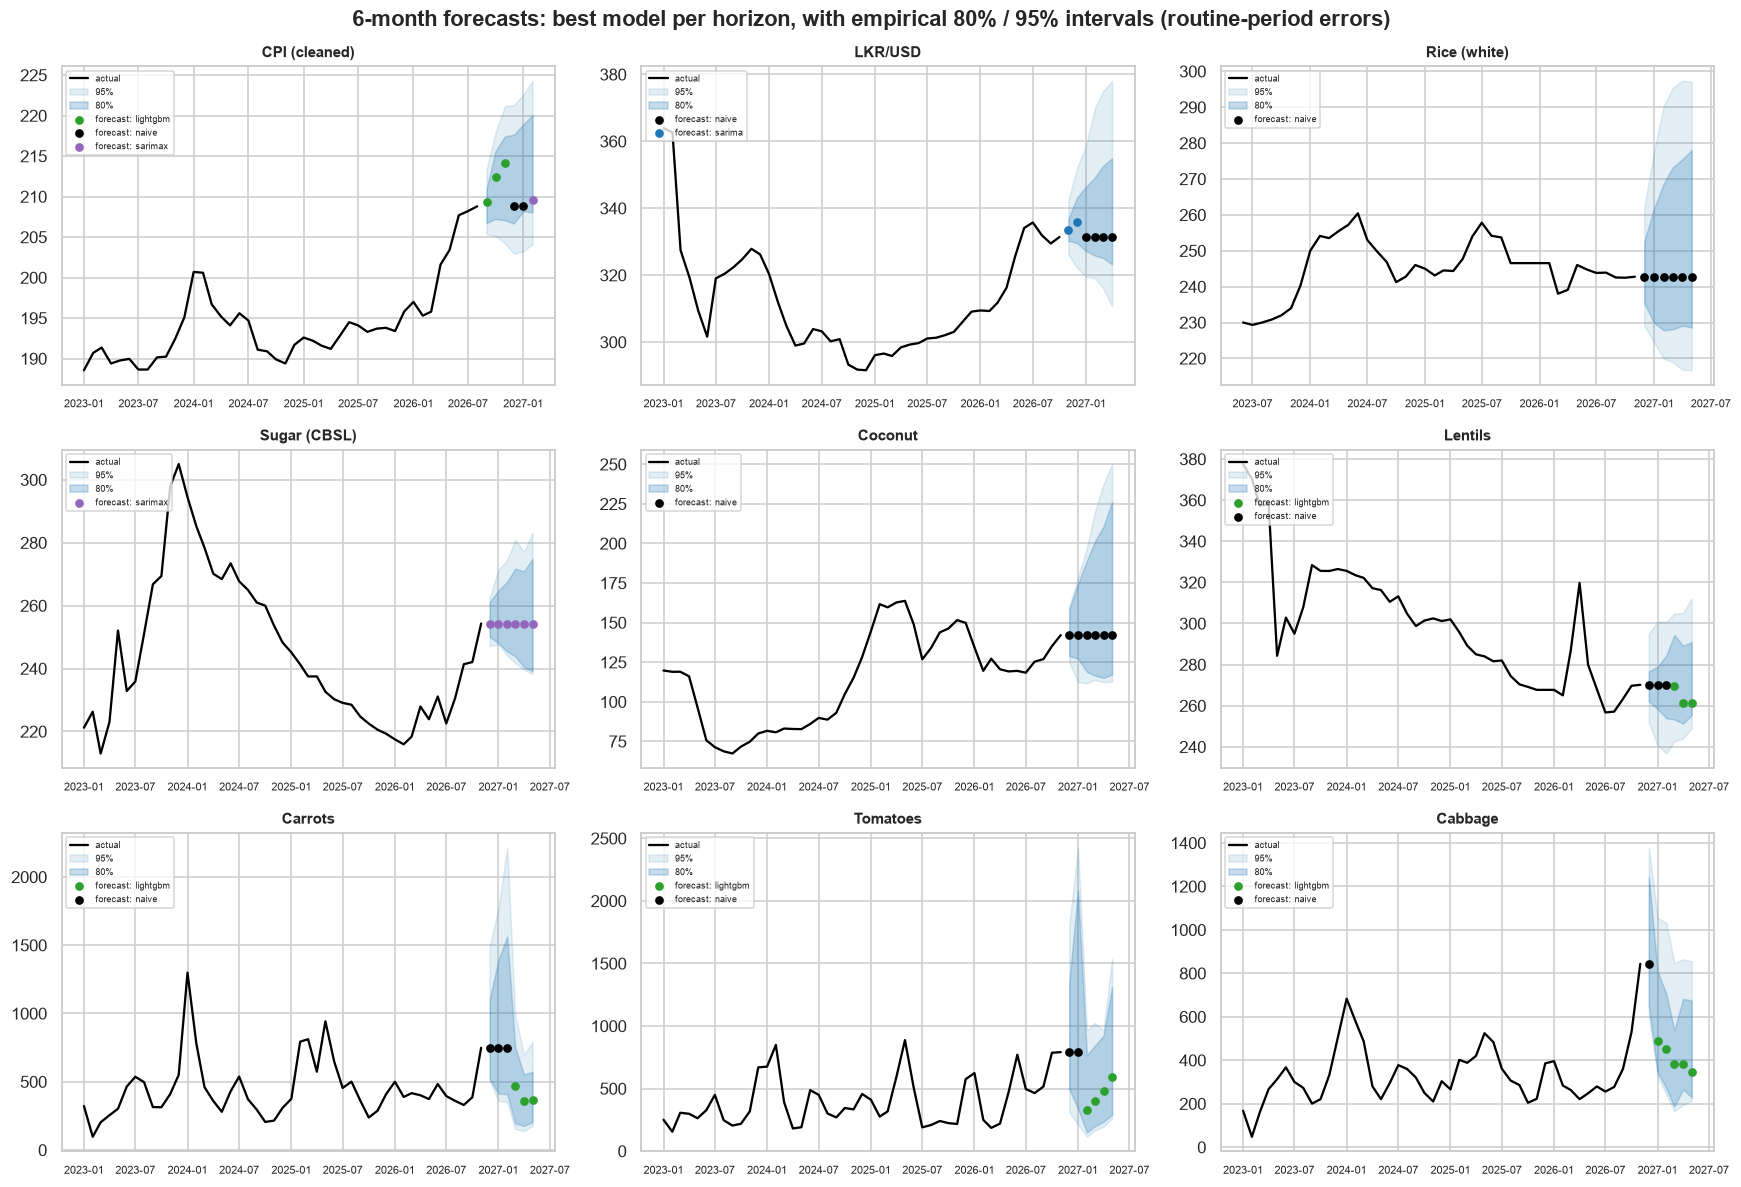

In [10]:
show = ["CPI (cleaned)", "LKR/USD", "Rice (white)", "Sugar (CBSL)", "Coconut", "Lentils", "Carrots", "Tomatoes", "Cabbage"]
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, s in zip(axes.flat, show):
    hist = specs[s].y.loc["2023-01":]
    ax.plot(hist.index, hist, color="black", lw=1.5, label="actual")
    d = selected[selected["series"] == s]
    ax.fill_between(d["target_date"], d["emp_lo95"], d["emp_hi95"], color="tab:blue", alpha=0.12, label="95%")
    ax.fill_between(d["target_date"], d["emp_lo80"], d["emp_hi80"], color="tab:blue", alpha=0.25, label="80%")
    # Each horizon may use a different model, so points are not joined into one path
    for m, g in d.groupby("model"):
        ax.scatter(g["target_date"], g["forecast"], color=colors[m], s=22, zorder=3, label=f"forecast: {m}")
    ax.set_title(s, fontsize=10)
    ax.legend(fontsize=6, loc="upper left")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis="x", labelsize=7)
fig.suptitle("6-month forecasts: best model per horizon, with empirical 80% / 95% intervals (routine-period errors)",
             fontweight="bold")
fig.tight_layout(); save(fig, "23_forecasts")

## 6. Key findings

**1. For most Sri Lankan price series, "no change" is very hard to beat.** Across 24,777 scored backtest forecasts, the naive forecast is the best or joint-best average model for LKR/USD, white rice, wheat flour, coconut, imported onion and lentils (routine periods). This is an informative result: these prices behave close to random walks month to month. Models are only useful where they add structure the naive forecast lacks.

**2. Where models clearly help**
| Series | Winning model | Gain vs naive (MAE) | Why |
|---|---|---|---|
| Sugar (CBSL) | SARIMAX (world sugar + FX, lag 1) | −20% at 1 m, −10% at 3 m | validated Phase 3 drivers |
| CPI (cleaned) | LightGBM (lagged FX, world food, momentum) | −12% at 1 m, −9% at 2 m | FX leads CPI by 1–2 m |
| Cabbage, carrots, tomatoes | pooled LightGBM | −9% to −25% at 3–6 m | learns the Dec–Jan peak and Sep–Oct trough |
| Local potato | seasonal naive | −35% at 2–4 m | stable seasonal cycle |
| Lentils | LightGBM | −11% to −14% at 4–6 m | gradual trends |

**3. SARIMA alone underperforms** (often 1.2–1.8× naive MAE). Fitted on short or volatile series it extrapolates recent spikes; for example, it projects the Nov-2026 cabbage spike upwards. The trend term also over-extrapolates in regime changes.

**4. The 2022 crisis stress test:** every model breaks down. Six-month MAPE is 13–15% for CPI, 19–24% for LKR/USD, 34–38% for rice and 43–46% for wheat flour, compared with 2–6% in routine periods. At **one month**, SARIMA/SARIMAX hold up best for CPI (1.7% vs 2.7% naive) and LightGBM/SARIMA for wheat flour (7% vs 11%). No model anticipated the shock; routine-period intervals understate crisis risk.

**5. LSTM:** tested and **not included**. It does not beat naive on CPI (MAE 2.03 vs 1.97) and is much worse on rice (8.14 vs 4.55).

**6. Current outlook** (best model per horizon, 80% empirical intervals):
- **CPI:** ~209 in Sep-2026 (+0.3%), rising to ~214 by Nov-2026 (LightGBM, momentum + FX; 80% band 207–217). From 4 months ahead the best backtest model switches to naive/SARIMAX (~209–210). The step down reflects the model switch, not a predicted price fall.
- **LKR/USD:** ~331–336.
- **Rice and coconut:** flat at about 243 and 142 LKR. Coconut has a wide upward-skewed band (118–189 by Feb-2027).
- **Seasonal vegetables:** after the Nov-2026 spike (cabbage 844, carrots 749, tomatoes 791 LKR/kg), the pooled LightGBM expects prices to **fall back over Jan–May 2027** (cabbage ~350–490). This is mostly reversion of the spike towards the 12-month average, and the 80% bands are very wide (e.g. cabbage Jan-2027: 347–810).